# 6BUIS017W CWK1: Task 1, Data Preparation and Feature Engineering

**Reproducibility.** The outputs shown come from the run on 22 November 2026 (ticker list retrieved 2026-11-22 20:18 UTC; prices downloaded 20:21 UTC; yfinance 0.2.66, pandas 2.2.3). Running the download cells again fetches a new Wikipedia list and fresh Yahoo data, which may differ slightly. To reproduce the exact results, place the repository's `data/` folder next to this notebook, run the setup cell, then run the **Appendix: reload saved snapshot** cell at the end *instead of* the three 1.1 download cells, and continue from 1.2.


In [ ]:
# Packages not preinstalled in Colab
!pip -q install yfinance lxml

In [ ]:
import os, io, re, json, sys, time, platform, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import yfinance as yf

START = "2021-01-01"   # first day of the study (included)
END   = "2025-01-01"   # end date (exclusive)
BENCH = "^GSPC"        # S&P 500 benchmark

os.makedirs("data", exist_ok=True)

versions = {"python": sys.version.split()[0], "pandas": pd.__version__,
            "numpy": np.__version__, "yfinance": yf.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66'}


## 1.1 Ticker selection and data acquisition

The S&P 500 constituent list is read from Wikipedia with `pandas.read_html` and the retrieval date is recorded. Daily Close, Adj Close, Volume, dividends and splits are downloaded from Yahoo Finance with `yfinance` (the library used in the Week 4 and 5 tutorials), with `auto_adjust=False` so Close and Adj Close stay separate. The benchmark is ^GSPC. The study period is 1 January 2021 to 1 January 2025, end date exclusive.


In [ ]:
# S&P 500 constituent list from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

# Record the retrieval date and store the list
retrieval_date = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
sp500_df['yf_ticker'] = tickers
sp500_df['retrieved'] = retrieval_date
sp500_df.to_csv('data/sp500_constituents.csv', index=False)

print('Total tickers extracted:', len(tickers))
print('Retrieved:', retrieval_date)
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503
Retrieved: 2026-11-22 20:18 UTC


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
# Daily Close, Adj Close, Volume, dividends and splits from Yahoo Finance
# yfinance treats `end` as exclusive, so the last session is 31 Dec 2024
raw = yf.download(tickers, start=START, end=END, auto_adjust=False, actions=True)

adj_close = raw['Adj Close']   # adjusted prices -> weekly returns and beta (1.3)
close     = raw['Close']       # prices          -> Monetary = Close x Volume (1.4)
volume    = raw['Volume']      # volume          -> high-volume days (1.4)
actions   = raw[['Dividends', 'Stock Splits']]   # used for the corporate-action checks in 1.2

# Benchmark
bench_raw = yf.download(BENCH, start=START, end=END, auto_adjust=False)
bench_adj = bench_raw['Adj Close'].squeeze()

no_data = [t for t in tickers if t not in adj_close.columns or adj_close[t].isna().all()]

print('Shares shape (days x tickers):', adj_close.shape)
print('First day:', adj_close.index.min().date(), '| Last day:', adj_close.index.max().date())
print('Benchmark days:', bench_adj.notna().sum())
print('Tickers with no data:', len(no_data), no_data)



[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'Q', 'VYLR', 'HONA', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Shares shape (days x tickers): (1005, 503)
First day: 2021-01-04 | Last day: 2024-12-31
Benchmark days: 1005
Tickers with no data: 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [ ]:
# Store the raw data and acquisition details for reproducibility
raw.to_csv('data/sp500_daily_raw_2021_2024.csv.gz', compression='gzip')
bench_raw.to_csv('data/gspc_daily_raw_2021_2024.csv')

acquisition_log = {
    'ticker_source': url,
    'ticker_retrieved': retrieval_date,
    'price_source': 'Yahoo Finance via yfinance ' + yf.__version__,
    'prices_downloaded': dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d %H:%M UTC'),
    'start_inclusive': START, 'end_exclusive': END, 'auto_adjust': False,
    'n_tickers': len(tickers), 'tickers_no_data': no_data,
}
json.dump(acquisition_log, open('data/acquisition_log.json', 'w'), indent=2)
print(json.dumps(acquisition_log, indent=2))
print(os.listdir('data'))

{
  "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "ticker_retrieved": "2026-11-22 20:18 UTC",
  "price_source": "Yahoo Finance via yfinance 0.2.66",
  "prices_downloaded": "2026-11-22 20:21 UTC",
  "start_inclusive": "2021-01-01",
  "end_exclusive": "2025-01-01",
  "auto_adjust": false,
  "n_tickers": 503,
  "tickers_no_data": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ]
}
['sp500_constituents.csv', 'acquisition_log.json', 'gspc_daily_raw_2021_2024.csv', 'sp500_daily_raw_2021_2024.csv.gz']


## 1.2 Data validation and alignment

Every share is checked for duplicate dates, missing values, non-positive prices, volume errors and unequal histories. Each exclusion is logged with its reason, and no missing price is filled.

In [ ]:
# 1.2 Data validation: one row per ticker, every exclusion gets a written reason
bench_days = bench_adj.dropna().index
print('Duplicate dates (shares):', adj_close.index.duplicated().sum(),
      '| (benchmark):', bench_days.duplicated().sum())
print('Share dates not in benchmark calendar:', len(adj_close.index.difference(bench_days)))

rows = []
for t in tickers:
    if t in no_data:
        rows.append({'ticker': t, 'status': 'excluded',
                     'reason': 'no price data 2021-2024 (listed after study period)'})
        continue
    a, c, v = adj_close[t], close[t], volume[t]
    first, last = a.first_valid_index(), a.last_valid_index()
    rec = {'ticker': t, 'first_date': first.date(), 'last_date': last.date(),
           'missing_adj': int(a.loc[first:last].isna().sum()),
           'missing_close': int(c.loc[first:last].isna().sum()),
           'missing_volume': int(v.loc[first:last].isna().sum()),
           'nonpositive_price': int(((a <= 0) | (c <= 0)).sum()),
           'nonpositive_volume': int((v <= 0).sum())}
    reasons = []
    if first > bench_days[0]:  reasons.append(f'history starts {first.date()} (unequal history)')
    if last < bench_days[-1]:  reasons.append(f'history ends {last.date()} (unequal history)')
    if rec['missing_adj'] + rec['missing_close'] + rec['missing_volume'] > 0:
        reasons.append('missing values inside history (not filled)')
    if rec['nonpositive_price'] > 0:  reasons.append('non-positive price')
    if rec['nonpositive_volume'] > 0: reasons.append('zero or negative volume')
    rec['status'] = 'excluded' if reasons else 'included'
    rec['reason'] = '; '.join(reasons)
    rows.append(rec)

log = pd.DataFrame(rows)
print(log['status'].value_counts())
log[log.status == 'excluded'][['ticker', 'first_date', 'last_date', 'reason']]

Duplicate dates (shares): 0 | (benchmark): 0
Share dates not in benchmark calendar: 0
status
included    486
excluded     17
Name: count, dtype: int64


,ticker,first_date,last_date,reason
40,APP,2021-04-15,2024-12-31,history starts 2021-04-15 (unequal history)
116,COIN,2021-04-14,2024-12-31,history starts 2021-04-14 (unequal history)
123,CEG,2022-01-19,2024-12-31,history starts 2022-01-19 (unequal history)
181,EXE,2021-02-10,2024-12-31,history starts 2021-02-10 (unequal history)
192,FDXF,NaN,NaN,no price data 2021-2024 (listed after study pe...
193,FERG,2021-01-04,2024-12-31,zero or negative volume
210,GEHC,2022-12-15,2024-12-31,history starts 2022-12-15 (unequal history)
211,GEV,2024-03-27,2024-12-31,history starts 2024-03-27 (unequal history)
233,HONA,NaN,NaN,no price data 2021-2024 (listed after study pe...
379,Q,NaN,NaN,no price data 2021-2024 (listed after study pe...


In [ ]:
# Excluded shares and the reason for each
print(log[log.status == 'excluded'][['ticker', 'first_date', 'last_date', 'reason']].to_string(index=False))

ticker first_date  last_date                                              reason
   APP 2021-04-15 2024-12-31         history starts 2021-04-15 (unequal history)
  COIN 2021-04-14 2024-12-31         history starts 2021-04-14 (unequal history)
   CEG 2022-01-19 2024-12-31         history starts 2022-01-19 (unequal history)
   EXE 2021-02-10 2024-12-31         history starts 2021-02-10 (unequal history)
  FDXF        NaN        NaN no price data 2021-2024 (listed after study period)
  FERG 2021-01-04 2024-12-31                             zero or negative volume
  GEHC 2022-12-15 2024-12-31         history starts 2022-12-15 (unequal history)
   GEV 2024-03-27 2024-12-31         history starts 2024-03-27 (unequal history)
  HONA        NaN        NaN no price data 2021-2024 (listed after study period)
     Q        NaN        NaN no price data 2021-2024 (listed after study period)
  RDDT 2024-03-21 2024-12-31         history starts 2024-03-21 (unequal history)
  HOOD 2021-07-29 2024-12-31

In [ ]:
# FERG and SW: zero-volume days before their US listing
for t in ['FERG', 'SW']:
    zero = volume[t][volume[t] <= 0]
    print(t, '| zero-volume days:', len(zero), '| from', zero.index.min().date(), 'to', zero.index.max().date())

FERG | zero-volume days: 27 | from 2021-01-07 to 2021-03-05
SW | zero-volume days: 424 | from 2021-01-05 to 2024-07-05


In [ ]:
# 1.2 Corporate action checks: splits, dividends, and whether Close/Adj Close agree
included = log.loc[log.status == 'included', 'ticker'].tolist()
ca_rows = []
for t in included:
    splits = actions['Stock Splits'][t].fillna(0)
    divs   = actions['Dividends'][t].fillna(0)
    rc = close[t].pct_change(fill_method=None)
    ra = adj_close[t].pct_change(fill_method=None)
    big = rc.abs() > 0.40
    ca_rows.append({'ticker': t,
                    'n_splits': int((splits > 0).sum()),
                    'split_dates': ', '.join(str(d.date()) for d in splits[splits > 0].index),
                    'n_dividends': int((divs > 0).sum()),
                    'big_moves': int(big.sum()),
                    'big_moves_not_in_adj': int((big & ((rc - ra).abs() > 0.05)).sum())})
ca = pd.DataFrame(ca_rows)

print('Shares with a split in 2021-2024:', (ca.n_splits > 0).sum())
print('Shares paying dividends:', (ca.n_dividends > 0).sum(), 'of', len(ca))
print('Shares with a >40% one-day move:', (ca.big_moves > 0).sum())
print('Moves where Close and Adj Close disagree:', ca.big_moves_not_in_adj.sum())

bad = ca.loc[ca.big_moves_not_in_adj > 0, 'ticker']
log.loc[log.ticker.isin(bad), ['status', 'reason']] = ['excluded', 'Close/Adj Close disagree on a >40% move']
log = log.merge(ca, on='ticker', how='left')
log.to_csv('data/inclusion_exclusion_log.csv', index=False)

print(log['status'].value_counts())
print(ca[ca.n_splits > 0][['ticker', 'split_dates']].to_string(index=False))

Shares with a split in 2021-2024: 53
Shares paying dividends: 392 of 486
Shares with a >40% one-day move: 4
Moves where Close and Adj Close disagree: 0
status
included    486
excluded     17
Name: count, dtype: int64
ticker                        split_dates
   MMM                         2024-04-01
 GOOGL                         2022-07-18
  GOOG                         2022-07-18
  AMZN                         2022-06-06
   APH             2021-03-05, 2024-06-12
  ANET             2021-11-18, 2024-12-04
     T                         2022-04-11
   BDX                         2022-04-01
  TECH                         2022-11-30
  AVGO                         2024-07-15
   CMG                         2024-06-26
  CTAS                         2024-09-12
   COO                         2024-02-20
  CPRT             2022-11-04, 2023-08-22
  CSGP                         2021-06-28
   CSX                         2021-06-29
   DHR                         2023-10-02
  DECK                     

**Corporate actions note.** Yahoo records some spin-offs as "stock splits", for example GE in 2023 and 2024 (spin-offs of GE HealthCare and GE Vernova) and MMM in April 2024 (spin-off of Solventum). Weekly returns use Adj Close, which is adjusted for splits, dividends and these spin-off events, so they do not appear as artificial price drops. No share showed a large Close move that was missing from Adj Close, so no share was excluded for a corporate-action problem.

In [ ]:
# 1.2 Weekly alignment: Friday-ending weeks, last available price in each week
start_ts, end_ts = pd.Timestamp(START), pd.Timestamp(END) - pd.Timedelta(days=1)

weekly_px = adj_close[included].resample('W-FRI').last()
weekly_bench = bench_adj.resample('W-FRI').last()

# keep only weeks where the benchmark traded, and only complete calendar weeks (Sat..Fri inside the study)
weekly_bench = weekly_bench.dropna()
week_start = weekly_bench.index - pd.Timedelta(days=6)
complete = (week_start >= start_ts) & (weekly_bench.index <= end_ts)
print('Dropped incomplete weeks:', [d.date() for d in weekly_bench.index[~complete]])
weekly_bench = weekly_bench[complete]
weekly_px = weekly_px.loc[weekly_bench.index]       # shares use the benchmark's week labels

print('Identical week labels:', weekly_px.index.equals(weekly_bench.index))
print('Weeks:', len(weekly_bench), '| first:', weekly_bench.index[0].date(), '| last:', weekly_bench.index[-1].date())
print('Shares with a missing weekly price:', int((weekly_px.isna().sum() > 0).sum()))

Dropped incomplete weeks: [datetime.date(2025, 1, 3)]
Identical week labels: True
Weeks: 208 | first: 2021-01-08 | last: 2024-12-27
Shares with a missing weekly price: 0


In [ ]:
# Survivorship bias evidence: current list applied to 2021-2024
late = log[log.reason.str.contains('starts|no price data|zero or negative', na=False)]
print('Constituent list retrieved:', retrieval_date)
print('Shares in current list:', len(tickers))
print('Excluded because they joined/listed after Jan 2021:', len(late))
print(', '.join(late.ticker))
print('Shares analysed:', (log.status == 'included').sum())

Constituent list retrieved: 2026-11-22 20:18 UTC
Shares in current list: 503
Excluded because they joined/listed after Jan 2021: 17
APP, COIN, CEG, EXE, FDXF, FERG, GEHC, GEV, HONA, Q, RDDT, HOOD, SNDK, SW, SOLV, VLTO, VYLR
Shares analysed: 486


### Survivorship bias

The ticker universe is the current S&P 500 constituent list, retrieved from Wikipedia on 22 November 2026, applied to price data from 2021–2024. This introduces survivorship bias. Firms that were in the index in January 2021 but were later acquired, delisted or removed (the index's "departures") do not appear in today's list and are therefore missing from the sample. At the same time, 17 current constituents (the "additions") had to be excluded because they listed or began US trading after the study start: initial public offerings such as COIN, HOOD and RDDT, spin-offs such as CEG, GEHC, GEV, SOLV and VLTO, and FERG and SW, whose earlier Yahoo prices predate their US listing and carry zero volume. The remaining 486 shares are firms that survived to 2026 and traded throughout the period. Because firms that failed or underperformed are more likely to have left the index, the sample leans towards successful companies, so mean weekly returns are likely to be higher, and the share of distressed firms lower, than for the index as it stood in 2021. The weekly return, beta and RFM features, and the clusters built on them, therefore describe today's surviving constituents rather than the full historical index, and they should not be read as representative of all S&P 500 firms over 2021–2024. A point-in-time constituent list would remove this bias, but it was not available from the required source.


## 1.3 Weekly return and weekly beta

### 1.3.1 Mean weekly return


In [ ]:
# 1.3.1 Weekly return = this week's Adj Close / last week's Adj Close - 1
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]       # first week has no previous week
bench_ret  = weekly_bench.pct_change(fill_method=None).iloc[1:]

print('Week labels identical:', weekly_ret.index.equals(bench_ret.index))
print('Weekly returns:', len(weekly_ret), '| first:', weekly_ret.index[0].date(), '| last:', weekly_ret.index[-1].date())
print('Missing weekly returns:', int(weekly_ret.isna().sum().sum()))

mean_weekly_return = weekly_ret.mean()      # arithmetic mean, the clustering feature
print(mean_weekly_return.describe())
print('Benchmark mean weekly return:', round(bench_ret.mean(), 5))

Week labels identical: True
Weekly returns: 207 | first: 2021-01-15 | last: 2024-12-27
Missing weekly returns: 0
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64
Benchmark mean weekly return: 0.0024


### 1.3.2 Weekly beta

In [ ]:
# 1.3.2 Weekly beta = cov(share, benchmark) / var(benchmark), full study period
bench_var = bench_ret.var(ddof=1)
rows = []
for t in included:
    pair = pd.concat([weekly_ret[t], bench_ret], axis=1).dropna()     # aligned weeks only, nothing filled
    cov = pair.iloc[:, 0].cov(pair.iloc[:, 1])
    rows.append({'ticker': t, 'mean_weekly_return': mean_weekly_return[t],
                 'weekly_beta': cov / bench_var, 'n_weeks': len(pair)})
risk_return = pd.DataFrame(rows).set_index('ticker')

# independent check: beta should equal the slope of a regression of share returns on benchmark returns
check = {t: np.polyfit(bench_ret, weekly_ret[t], 1)[0] for t in ['AAPL', 'MSFT', 'NVDA']}
print('Beta check (cov/var vs regression slope):')
print(pd.DataFrame({'cov_var': risk_return.loc[list(check), 'weekly_beta'], 'regression': pd.Series(check)}).round(4))

print('\nAligned weekly observations per share: min', risk_return.n_weeks.min(), '| max', risk_return.n_weeks.max())
print(risk_return[['mean_weekly_return', 'weekly_beta']].describe().round(4))
risk_return.to_csv('data/risk_return_features.csv')

Beta check (cov/var vs regression slope):
      cov_var  regression
AAPL   1.1748      1.1748
MSFT   1.1286      1.1286
NVDA   2.1260      2.1260

Aligned weekly observations per share: min 207 | max 207
       mean_weekly_return  weekly_beta
count            486.0000     486.0000
mean               0.0029       0.9737
std                0.0027       0.4073
min               -0.0045       0.0555
25%                0.0012       0.6666
50%                0.0026       0.9506
75%                0.0042       1.1795
max                0.0178       3.7786


In [ ]:
# Lowest and highest weekly betas
print(risk_return.sort_values('weekly_beta').iloc[[0, 1, 2, -3, -2, -1]].round(4))

        mean_weekly_return  weekly_beta  n_weeks
ticker                                          
GIS                 0.0015       0.0555      207
SJM                 0.0008       0.1756      207
MRK                 0.0021       0.1983      207
COHR                0.0039       2.1393      207
XYZ                -0.0016       2.5045      207
CVNA                0.0110       3.7786      207


## 1.4 Adapted RFM calculations

In [ ]:
# 1.4 Setup: observation date, 60-session window, and high-volume days
c_v, v_v = close[included], volume[included]

# observation date = last date on which every included share has Close and Volume
common = c_v.notna().all(axis=1) & v_v.notna().all(axis=1)
OBS_DATE = common[common].index.max()

# baseline = mean volume of the PRECEDING 20 sessions (shift(1) leaves out the day being tested)
baseline  = v_v.shift(1).rolling(20, min_periods=20).mean()
threshold = 2 * baseline
event = (v_v > threshold) & threshold.notna()      # high-volume day, computed per share and per day
event = event.loc[:OBS_DATE]

window = v_v.loc[:OBS_DATE].index[-60:]            # latest 60 trading sessions ending on OBS_DATE

print('Observation date:', OBS_DATE.date())
print('60-session window:', window[0].date(), 'to', window[-1].date(), '|', len(window), 'sessions')
print('Every share has a full 20-day baseline on every window day:', bool(threshold.loc[window].notna().all().all()))
print('Total high-volume days in the study, all shares:', int(event.sum().sum()))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31 | 60 sessions
Every share has a full 20-day baseline on every window day: True
Total high-volume days in the study, all shares: 18280


### 1.4.1 Recency

In [ ]:
# 1.4.1 Recency = calendar days from the latest high-volume day to the observation date
last_event = event.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
R = (OBS_DATE - last_event).dt.days          # calendar days, weekends and holidays included; NaN if no event

print('Shares with no high-volume day in the whole history (R missing, not 0):', int(R.isna().sum()))
print('Shares with an event ON the observation date (R = 0):', int((R == 0).sum()))
print(R.describe().round(1))
print('\nMost common latest-event dates:')
print(last_event.value_counts().head(5))

Shares with no high-volume day in the whole history (R missing, not 0): 0
Shares with an event ON the observation date (R = 0): 0
count    486.0
mean      20.4
std       21.3
min        4.0
25%       11.0
50%       11.0
75%       14.8
max      222.0
dtype: float64

Most common latest-event dates:
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64


### 1.4.2 Frequency and 1.4.3 Monetary


In [ ]:
# 1.4.2 Frequency = number of high-volume DAYS in the latest 60 sessions
F = event.loc[window].sum().astype(int)

# 1.4.3 Monetary = sum of Close x Volume over the same 60 sessions (approximate traded value, USD)
M = (c_v.loc[window] * v_v.loc[window]).sum()

rfm = pd.DataFrame({'last_event_date': last_event, 'Recency': R, 'Frequency': F, 'Monetary': M})
rfm.index.name = 'ticker'
rfm.to_csv('data/rfm_features.csv')

print('Shares with F = 0 (no event in the 60-day window but an older event):', int((rfm.Frequency == 0).sum()))
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(1))
rfm.loc[['AAPL', 'MSFT', 'NVDA', 'GIS']]

Shares with F = 0 (no event in the 60-day window but an older event): 10
       Recency  Frequency      Monetary
count    486.0      486.0  4.860000e+02
mean      20.4        3.0  3.940419e+10
std       21.3        1.3  1.291388e+11
min        4.0        0.0  1.297483e+09
25%       11.0        2.0  1.019517e+10
50%       11.0        3.0  1.668382e+10
75%       14.8        4.0  3.227689e+10
max      222.0        8.0  1.847697e+12


,last_event_date,Recency,Frequency,Monetary
ticker,,,,
AAPL,2024-12-20,11,2,6.233034e+11
MSFT,2024-12-20,11,2,5.348982e+11
NVDA,2024-05-23,222,0,1.825337e+12
GIS,2024-12-20,11,2,1.546400e+10


## 1.5 Metric interpretation and supporting evidence

### Worked example: AAPL

In [ ]:
# 1.5 Worked RFM example for one share
EX = 'AAPL'
ex = pd.DataFrame({'Close': close[EX], 'Volume': volume[EX],
                   'prev20_mean': baseline[EX], 'threshold_2x': threshold[EX],
                   'high_volume': event[EX]}).loc[window]
ex['traded_value'] = ex['Close'] * ex['Volume']

# Step 1: check the rolling baseline by hand on the latest event day
d = rfm.loc[EX, 'last_event_date']
i = volume.index.get_loc(d)
manual = volume[EX].iloc[i - 20:i].mean()             # the 20 sessions BEFORE the event day
print(f'Step 1  Baseline on {d.date()}: rolling = {baseline.loc[d, EX]:,.0f} | by hand = {manual:,.0f}')
print(f'        Threshold = 2 x {manual:,.0f} = {2*manual:,.0f}; volume that day = {volume.loc[d, EX]:,.0f} -> event')

# Step 2: Recency
print(f'Step 2  R = {OBS_DATE.date()} - {d.date()} = {(OBS_DATE - d).days} calendar days')

# Step 3: Frequency
print(f'Step 3  High-volume days in the 60-session window:')
print(ex[ex.high_volume][['Volume', 'prev20_mean', 'threshold_2x']].round(0).to_string())
print(f'        F = {int(ex.high_volume.sum())}')

# Step 4: Monetary
print(f'Step 4  M = sum of 60 daily Close x Volume = ${ex.traded_value.sum():,.0f}'
      f'  (matches table: {np.isclose(ex.traded_value.sum(), rfm.loc[EX, "Monetary"])})')
print(f'        e.g. {window[-1].date()}: ${ex.Close.iloc[-1]:.2f} x {ex.Volume.iloc[-1]:,.0f} = ${ex.traded_value.iloc[-1]:,.0f}')

Step 1  Baseline on 2024-12-20: rolling = 45,004,605 | by hand = 45,004,605
        Threshold = 2 x 45,004,605 = 90,009,210; volume that day = 147,495,300 -> event
Step 2  R = 2024-12-31 - 2024-12-20 = 11 calendar days
Step 3  High-volume days in the 60-session window:
               Volume  prev20_mean  threshold_2x
Date                                            
2024-11-25   90152800   43820740.0    87641480.0
2024-12-20  147495300   45004605.0    90009210.0
        F = 2
Step 4  M = sum of 60 daily Close x Volume = $623,303,377,707  (matches table: True)
        e.g. 2024-12-31: $250.42 x 39,480,700 = $9,886,756,822


### Validation checks

In [ ]:
# 1.5 Validation checks for the RFM rules
checks = {}
# 1. Threshold alignment: baseline uses the 20 sessions BEFORE the day (re-derived independently)
alt = v_v.rolling(20).mean().shift(1)
checks['baseline excludes the tested day (matches independent calc)'] = bool(np.allclose(alt.loc[window], baseline.loc[window]))
checks['no event flagged without a full 20-day baseline'] = int((event & threshold.loc[:OBS_DATE].isna()).sum().sum()) == 0
checks['events use strictly greater than 2x (no ties counted)'] = int((event & (v_v.loc[:OBS_DATE] <= threshold.loc[:OBS_DATE])).sum().sum()) == 0
# 2. No-event handling: R is NaN (never 0) when a share has no event
checks['shares with no event have R missing, not 0'] = bool((rfm.last_event_date.isna() == rfm.Recency.isna()).all())
checks['R is never negative'] = bool((rfm.Recency.dropna() >= 0).all())
# 3. Sufficient history
checks['window has exactly 60 sessions ending on observation date'] = len(window) == 60 and window[-1] == OBS_DATE
checks['20 sessions available before first window day'] = v_v.index.get_loc(window[0]) >= 20
checks['F never exceeds 60'] = bool((rfm.Frequency <= 60).all())
# 4. Common valid share set for both feature matrices
checks['same 486 shares in risk/return and RFM tables'] = set(risk_return.index) == set(rfm.index) == set(included)

for k, v in checks.items():
    print(('PASS  ' if v else 'FAIL  ') + k)

PASS  baseline excludes the tested day (matches independent calc)
PASS  no event flagged without a full 20-day baseline
PASS  events use strictly greater than 2x (no ties counted)
PASS  shares with no event have R missing, not 0
PASS  R is never negative
PASS  window has exactly 60 sessions ending on observation date
PASS  20 sessions available before first window day
PASS  F never exceeds 60
PASS  same 486 shares in risk/return and RFM tables


### Feature table and summaries

Feature table: 486 shares x 10 columns -> data/features_task1.csv
                    count          mean           std           min           25%           50%           75%           max     skew
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02   0.8675
weekly_beta         486.0  9.737000e-01  4.073000e-01  5.550000e-02  6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00   1.1036
Recency             486.0  2.040740e+01  2.134240e+01  4.000000e+00  1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02   3.6458
Frequency           486.0  2.989700e+00  1.330800e+00  0.000000e+00  2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00   0.4247
Monetary            486.0  3.940419e+10  1.291388e+11  1.297483e+09  1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  11.6838
log1p_Monetary      486.0  2.368210e+01  9.422000e-01  2.098370e+01  2.304520e+01  2.353770e+01  2.419760e+01  2.824500e+01   1.0791


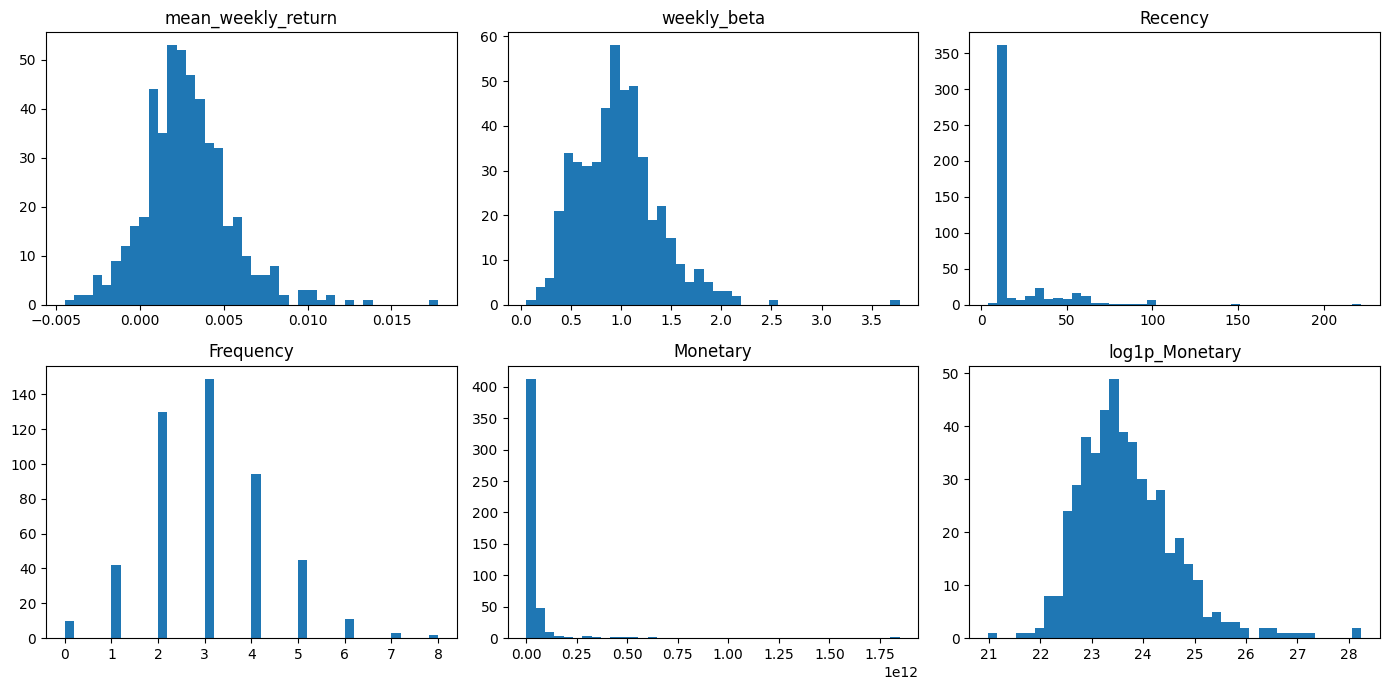

status
excluded     17
included    486
                        mean_weekly_return  weekly_beta  Frequency  log1p_Monetary
GICS Sector                                                                       
Communication Services              0.0029       0.8866        4.0         23.7789
Consumer Discretionary              0.0032       1.1404        3.0         23.8077
Consumer Staples                    0.0010       0.4689        3.0         23.5968
Energy                              0.0057       0.7503        2.0         23.7753
Financials                          0.0033       1.0083        3.0         23.5124
Health Care                         0.0010       0.7591        3.0         23.7200
Industrials                         0.0029       0.9992        3.0         23.4023
Information Technology              0.0038       1.3517        3.0         24.0242
Materials                           0.0017       0.9352        3.0         23.3459
Real Estate                         0.0021      

In [ ]:
# 1.5 Final Task 1 feature table: one row per included share
sector = sp500_df.set_index('yf_ticker')[['Security', 'GICS Sector']]
features = sector.join(risk_return, how='inner').join(rfm, how='inner')
features['log1p_Monetary'] = np.log1p(features['Monetary'])
features.to_csv('data/features_task1.csv')
print('Feature table:', features.shape[0], 'shares x', features.shape[1], 'columns -> data/features_task1.csv')

# Summary statistics with skew
cols = ['mean_weekly_return', 'weekly_beta', 'Recency', 'Frequency', 'Monetary', 'log1p_Monetary']
summary = features[cols].describe().T
summary['skew'] = features[cols].skew()
print(summary.round(4).to_string())

# Distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(features[col], bins=40); ax.set_title(col)
plt.tight_layout(); plt.savefig('data/task1_feature_distributions.png', dpi=150); plt.show()

# Inclusion/exclusion log summary
print(log.groupby('status').size().to_string())
print(features.groupby('GICS Sector')[['mean_weekly_return', 'weekly_beta', 'Frequency', 'log1p_Monetary']].median().round(4).to_string())

### What each metric captures and its limits

**Mean weekly return** is the arithmetic average of 207 Friday-to-Friday changes in Adjusted Close (2021–2024). It describes past average performance only; the median share returned 0.26% a week against 0.24% for ^GSPC. Being an average of past weeks, it says nothing about future returns and is sensitive to a few extreme weeks (e.g. CVNA, 1.10% a week after a near-collapse and recovery).

**Weekly beta** is the covariance of a share's weekly returns with ^GSPC divided by the variance of ^GSPC, over the full period. It measures how strongly a share moved with the market: the median is 0.95, ranging from 0.06 (GIS) to 3.78 (CVNA); by sector, Information Technology has the highest median (1.35) and Consumer Staples the lowest (0.47). Beta captures only market-related co-movement, not total risk, and differences in beta alone do not show that two shares diversify each other; that depends on how their returns move together.

**Recency (R)** is the number of calendar days from a share's latest unusually high-volume day (volume > 2 × the mean of the previous 20 sessions) to the observation date, 31 December 2024. 353 of 486 shares had their latest event on 20 December 2024, a market-wide options-expiry and index-rebalancing day, so R mainly reflects calendar events and has little variation (median 11 days, skew 3.6).

**Frequency (F)** counts high-volume days in the latest 60 sessions (median 3, range 0–8). The rule is relative to each share's own normal volume, so very heavily traded shares rarely qualify: NVDA had F = 0 and R = 222 despite being among the most traded shares. The 2× cut-off is also sharp; AAPL's 25 November 2024 event exceeded its threshold by only about 3%.

**Monetary (M)** is the sum of Close × Volume over the same 60 sessions, an approximate dollar value traded (median \$16.7 billion, up to \$1.85 trillion). It is a liquidity proxy, not market value, profit or investor inflows, and it is extremely skewed (skew 11.7), hence log1p(M) in Task 2.

**Limits as investment signals.** All five features describe the past at a single observation date. RFM measures trading activity, not company quality or future returns, and the features are computed on today's surviving constituents (survivorship bias, see 1.2). Clusters built on them are descriptive groupings, not predictions or portfolio recommendations.

### Data snapshot inventory and fingerprints

In [ ]:
# SHA-256 hash of each data snapshot file, stored in acquisition_log.json for provenance
import hashlib
fingerprints = {f: hashlib.sha256(open('data/' + f, 'rb').read()).hexdigest()
                for f in sorted(os.listdir('data')) if not f.endswith('.json')}
acquisition_log['sha256'] = fingerprints
json.dump(acquisition_log, open('data/acquisition_log.json', 'w'), indent=2)
for f, h in fingerprints.items():
    print(f'{f:40s} {h[:16]}...')

features_task1.csv                       8644abd9f55f0b41...
gspc_daily_raw_2021_2024.csv             b25b2ac034e56b5d...
inclusion_exclusion_log.csv              9fd8d439024da7cc...
rfm_features.csv                         aa0d9be419658292...
risk_return_features.csv                 f620c2fb4e77bcc4...
sp500_constituents.csv                   61a6c44a1a293d26...
sp500_daily_raw_2021_2024.csv.gz         61657387e96b9ba7...
task1_feature_distributions.png          683ba8d25a27d729...


In [ ]:
# Inventory of the preserved data snapshot
for f in sorted(os.listdir('data')):
    print(f'{f:40s} {os.path.getsize("data/" + f) / 1e6:6.2f} MB')

acquisition_log.json                       0.00 MB
features_task1.csv                         0.06 MB
gspc_daily_raw_2021_2024.csv               0.10 MB
inclusion_exclusion_log.csv                0.04 MB
rfm_features.csv                           0.02 MB
risk_return_features.csv                   0.02 MB
sp500_constituents.csv                     0.07 MB
sp500_daily_raw_2021_2024.csv.gz          14.00 MB
task1_feature_distributions.png            0.09 MB


## Appendix: reload saved snapshot

Use this instead of the 1.1 download cells to reproduce the submitted results from the files in `data/`.


In [ ]:
# Reload the preserved dataset instead of downloading again (run after the setup cell, then continue from 1.2)
sp500_df = pd.read_csv('data/sp500_constituents.csv')
tickers = sp500_df['yf_ticker'].tolist()
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
acquisition_log = json.load(open('data/acquisition_log.json'))
retrieval_date, no_data = acquisition_log['ticker_retrieved'], acquisition_log['tickers_no_data']

raw = pd.read_csv('data/sp500_daily_raw_2021_2024.csv.gz', header=[0, 1], index_col=0, parse_dates=True)
adj_close, close, volume = raw['Adj Close'], raw['Close'], raw['Volume']
actions = raw[['Dividends', 'Stock Splits']]
bench_raw = pd.read_csv('data/gspc_daily_raw_2021_2024.csv', header=[0, 1], index_col=0, parse_dates=True)
bench_adj = bench_raw['Adj Close'].squeeze()
print('Reloaded', len(tickers), 'tickers | retrieved', retrieval_date, '| days', len(adj_close))